### Importing Relevant Libraries

In [1]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.signal as signal

In [2]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.max_open_warning': 0})

### Exploratory Data Analysis

#### Ground-truth distribution Inspection

In [3]:
def run_step1_eda():
    # Load dataset table
    df = pd.read_csv("db.csv")
    group_col = "patient_id" if "patient_id" in df.columns else "subject_id"
    if group_col not in df.columns and "file_id" in df.columns:
        group_col = "file_id"
        
    print("==================================================")
    print(" STEP 1: GROUND-TRUTH DISTRIBUTION INSPECTION")
    print("==================================================")
    
    # 1. Target Distribution EDA (Respiratory & Derived Glucose)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    if "respiratory" in df.columns:
        sns.histplot(df["respiratory"].dropna(), kde=True, ax=axes[0], color="crimson")
        axes[0].set_title("Ground Truth: Respiratory Rate Distribution")
        axes[0].set_xlabel("Respiratory Rate")
    else:
        axes[0].text(0.5, 0.5, "Column 'respiratory' missing", ha='center')
        
    if "glycated_hemoglobin" in df.columns:
        # Convert HbA1c (%) to Estimated Average Glucose (mg/dL)[cite: 1]
        eag_values = (28.7 * df["glycated_hemoglobin"]) - 46.7
        sns.histplot(eag_values.dropna(), kde=True, ax=axes[1], color="dodgerblue")
        axes[1].set_title("Ground Truth: Derived Blood Glucose (eAG mg/dL)[cite: 1]")
        axes[1].set_xlabel("Estimated Average Glucose (mg/dL)")
    else:
        axes[1].text(0.5, 0.5, "Column 'glycated_hemoglobin' missing", ha='center')
        
    plt.tight_layout()
    plt.show()

    print("\n==================================")
    print(" VIDEO FPS & SIGNAL DRIFT INSPECTION")
    print("====================================")
    
    file_suffixes = [
        "_USBVideo_before", "_USBVideo_after",
        "_IriunWebcam_before", "_IriunWebcam_after",
        "_FullHDwebcam_before", "_FullHDwebcam_after"
    ]
    
    fps_records = []
    drift_records = []
    
    for idx, row in df.iterrows():
        subj_raw = row[group_col]
        subj_id = str(int(float(subj_raw))) if str(subj_raw).replace('.', '', 1).isdigit() else str(subj_raw).strip()
        
        for suffix in file_suffixes:
            vid_paths = glob.glob(f"video/{subj_id}{suffix}.avi")
            if not vid_paths:
                continue
                
            cap = cv2.VideoCapture(vid_paths[0])
            fps = cap.get(cv2.CAP_PROP_FPS)
            frameCount = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            
            # Estimate lighting/brightness drift across frames
            frame_brightness = []
            while cap.isOpened() and len(frame_brightness) < 150: # Sample first 150 frames
                ret, frame = cap.read()
                if not ret or frame is None:
                    break
                gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
                frame_brightness.append(np.mean(gray))
            cap.release()
            
            brightness_drift = np.std(frame_brightness) if frame_brightness else 0.0
            
            fps_records.append({"Condition": suffix, "FPS": fps if fps > 0 else 30.0})
            drift_records.append({"Condition": suffix, "Brightness_Std": brightness_drift})
            
    # Convert inspection logs to DataFrame for visualization
    df_fps = pd.DataFrame(fps_records)
    df_drift = pd.DataFrame(drift_records)
    
    if not df_fps.empty:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        sns.boxplot(data=df_fps, x="Condition", y="FPS", ax=axes[0], palette="Set2")
        axes[0].set_title("Frame Rate (FPS) Stability Across Conditions")
        axes[0].tick_params(axis='x', rotation=45)
        
        sns.boxplot(data=df_drift, x="Condition", y="Brightness_Std", ax=axes[1], palette="Set3")
        axes[1].set_title("Lighting Drift (Brightness Standard Deviation)")
        axes[1].tick_params(axis='x', rotation=45)
        
        plt.tight_layout()
        plt.show()
    else:
        print("No video files found for technical inspection. Verify directory paths.")

 STEP 1: GROUND-TRUTH DISTRIBUTION INSPECTION


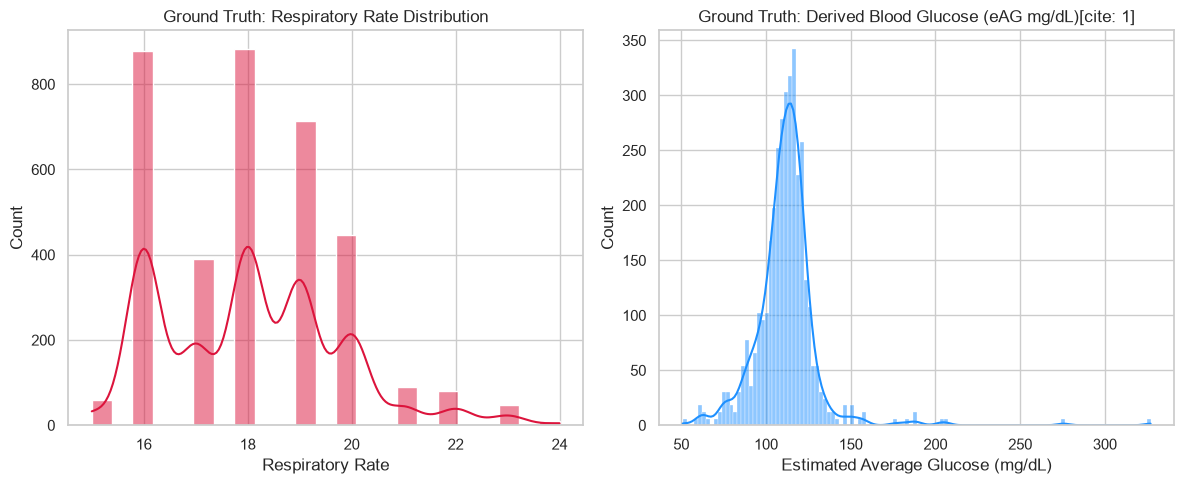


 VIDEO FPS & SIGNAL DRIFT INSPECTION


C:\Users\neoyu\AppData\Local\Temp\ipykernel_28348\1301167033.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_fps, x="Condition", y="FPS", ax=axes[0], palette="Set2")
C:\Users\neoyu\AppData\Local\Temp\ipykernel_28348\1301167033.py:85: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_drift, x="Condition", y="Brightness_Std", ax=axes[1], palette="Set3")


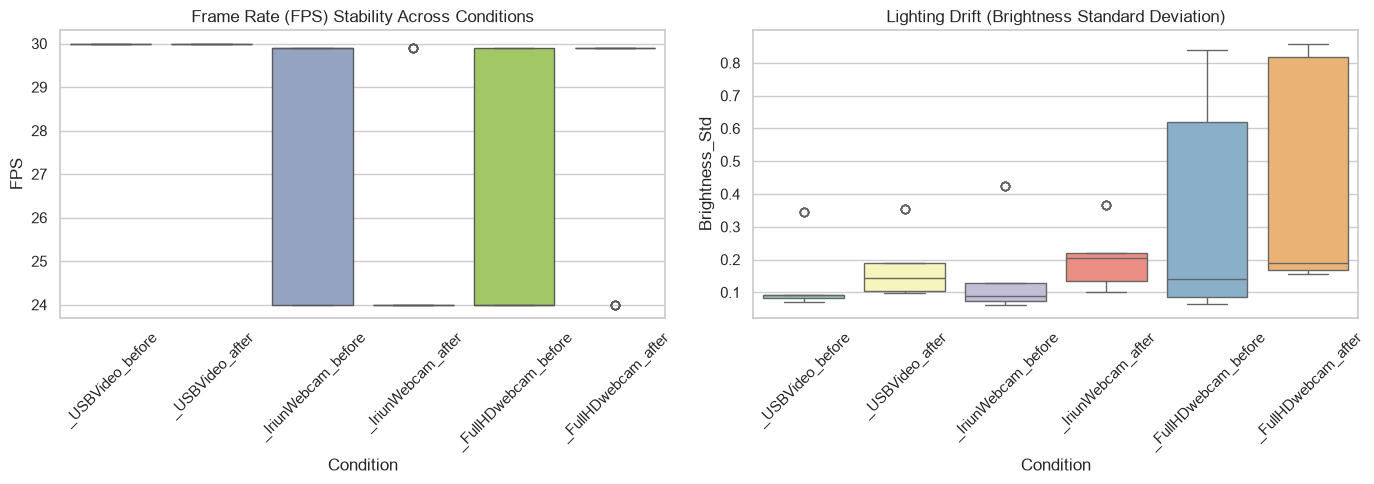

In [4]:
if __name__ == "__main__":
    run_step1_eda()

- Target Distribution Analysis: Plots histograms and kernel density estimations for your two core biological features (respiratory rate and HbA1c-converted blood glucose / eAG) to check for skewness, outliers, or missing ranges
- Frame Rate (FPS) Check: Verifies if hardware webcams (IriunWebcam, FullHDwebcam, USBVideo) maintain steady frame rates or experience dropped frames across "Before" and "After" experiments.
- Lighting & Signal Drift Analysis: Calculates brightness standard deviations across early video frames to quantify ambient lighting variations that could distort rPPG skin color extractions.

### Quick Initial Baseline Models

In [5]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler

# Feature extractor for Contact PPG (.txt files)
def extract_contact_ppg_baseline_features(txt_path):
    try:
        data = np.loadtxt(txt_path)
        sig = data[:, -1] if data.ndim > 1 and data.shape[1] > 1 else data
    except Exception:
        sig = np.loadtxt(txt_path, delimiter=",")[:, -1]
        
    if len(sig) < 100:
        return [0.0, 0.0, 0.0, 0.0]
        
    sig_mean = np.mean(sig)
    sig_var = np.var(sig)
    sig_std = np.std(sig)
    
    # Simple dominant frequency via Welch
    freqs, psd = signal.welch(sig, fs=100.0, nperseg=min(len(sig), 256))
    dom_freq = freqs[np.argmax(psd)] if len(freqs) > 0 else 0.0
    
    return [sig_mean, sig_var, sig_std, dom_freq]

#### Basline Statistical Features
- sig_mean: The arithmetic mean of the signal amplitudes.
- sig_var: The statistical variance, capturing overall signal dispersion.
- sig_std: The standard deviation of the signal.
- dom_freq (Dominant Frequency): It applies Welch's method (signal.welch) assuming a sampling rate (fs) of 100.0 Hz to estimate the power spectral density, extracting the frequency corresponding to the highest peak power (which typically correlates with the cardiac pulse rate).

In [6]:
# Feature extractor for Video rPPG (.avi files)
def extract_rppg_baseline_features(video_path):
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    fps = 30.0 if (fps == 0 or np.isnan(fps)) else fps
    
    rgb_means = []
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret or frame is None:
            break
        h, w, _ = frame.shape
        roi = frame[int(h*0.15):int(h*0.85), int(w*0.2):int(w*0.8)]
        rgb_means.append(np.mean(roi[:, :, 1])) # Green channel proxy
    cap.release()
    
    raw_sig = np.array(rgb_means)
    if len(raw_sig) < int(fps * 5):
        return [0.0, 0.0, 0.0, 0.0]
        
    nyquist = 0.5 * fps
    low_resp = 0.1 / nyquist
    high_resp = min(0.4 / nyquist, 0.99)
    b_resp, a_resp = signal.butter(2, [low_resp, high_resp], btype='band')
    resp_filtered = signal.filtfilt(b_resp, a_resp, raw_sig)
    
    freqs, psd = signal.welch(resp_filtered, fs=fps, nperseg=min(len(resp_filtered), 512))
    resp_dom_freq = freqs[np.argmax(psd)] if len(freqs) > 0 else 0.0
    estimated_resp_rate = resp_dom_freq * 60.0
    
    sig_mean = np.mean(raw_sig)
    sig_variance = np.var(raw_sig)
    
    low_card = 0.7 / nyquist
    high_card = min(3.5 / nyquist, 0.99)
    b_card, a_card = signal.butter(2, [low_card, high_card], btype='band')
    cardiac_filtered = signal.filtfilt(b_card, a_card, raw_sig)
    cardiac_std = np.std(cardiac_filtered)
    
    return [estimated_resp_rate, sig_mean, sig_variance, cardiac_std]

- sig_mean: The global mean of the raw green-channel signal, capturing baseline illumination.
- sig_variance: The variance of the raw signal, reflecting overall brightness fluctuation or motion noise.
- cardiac_std: It applies a separate cardiac bandpass filter (0.7 Hz to 3.5 Hz, or 42 to 210 bpm) to isolate pulse signals, then computes the standard deviation of that filtered wave to represent pulse strength or variability.

In [7]:
def run_step2_dual_modality_baselines():
    df = pd.read_csv("db.csv")
    group_col = "patient_id" if "patient_id" in df.columns else "subject_id"
    if group_col not in df.columns and "file_id" in df.columns:
        group_col = "file_id"
        
    file_suffixes = [
        "_USBVideo_before", "_USBVideo_after",
        "_IriunWebcam_before", "_IriunWebcam_after",
        "_FullHDwebcam_before", "_FullHDwebcam_after"
    ]
    
    X_rppg, X_ppg, y_resp, y_glucose, groups = [], [], [], [], []
    
    print("Extracting features for Video rPPG and Contact PPG baselines...")
    for idx, row in df.iterrows():
        raw_subj = row[group_col]
        subj_id = str(int(float(raw_subj))) if str(raw_subj).replace('.', '', 1).isdigit() else str(raw_subj).strip()
        
        resp_gt = row.get("respiratory", np.nan)
        hba1c_gt = row.get("glycated_hemoglobin", np.nan)
        
        if pd.isna(resp_gt) or pd.isna(hba1c_gt):
            continue
            
        glucose_gt = (28.7 * hba1c_gt) - 46.7
        
        # 1. Gather Video rPPG Features
        rppg_subj_feats = []
        for suffix in file_suffixes:
            vid_paths = glob.glob(f"video/{subj_id}{suffix}.avi")
            if vid_paths:
                feats = extract_rppg_baseline_features(vid_paths[0])
                rppg_subj_feats.append(feats)
                
        # 2. Gather Contact PPG Features
        ppg_subj_feats = []
        for suffix in file_suffixes:
            txt_paths = glob.glob(f"ppg_sync/{subj_id}{suffix}.txt")
            if txt_paths:
                feats = extract_contact_ppg_baseline_features(txt_paths[0])
                ppg_subj_feats.append(feats)
                
        # Only add subjects that have valid extractions for both modalities
        if rppg_subj_feats and ppg_subj_feats:
            X_rppg.append(np.mean(rppg_subj_feats, axis=0))
            X_ppg.append(np.mean(ppg_subj_feats, axis=0))
            y_resp.append(resp_gt)
            y_glucose.append(glucose_gt)
            groups.append(subj_id)
            
    X_rppg = np.array(X_rppg)
    X_ppg = np.array(X_ppg)
    y_resp = np.array(y_resp)
    y_glucose = np.array(y_glucose)
    groups = np.array(groups)
    
    if len(np.unique(groups)) < 2:
        print("Error: Not enough distinct subjects found for LOGO cross-validation.")
        return
        
    logo = LeaveOneGroupOut()
    
    def evaluate_modality(X_data, modality_name):
        resp_preds, resp_actuals = [], []
        for train_idx, test_idx in logo.split(X_data, y_resp, groups):
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_data[train_idx])
            X_test = scaler.transform(X_data[test_idx])
            
            model = Ridge(alpha=1.0)
            model.fit(X_train, y_resp[train_idx])
            resp_preds.extend(model.predict(X_test))
            resp_actuals.extend(y_resp[test_idx])
            
        glu_preds, glu_actuals = [], []
        for train_idx, test_idx in logo.split(X_data, y_glucose, groups):
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X_data[train_idx])
            X_test = scaler.transform(X_data[test_idx])
            
            model = Ridge(alpha=1.0)
            model.fit(X_train, y_glucose[train_idx])
            glu_preds.extend(model.predict(X_test))
            glu_actuals.extend(y_glucose[test_idx])
            
        print(f"\n--- {modality_name} Baseline Results ---")
        print(f"Respiratory Rate Model -> MSE: {mean_squared_error(resp_actuals, resp_preds):.4f} | MAE: {mean_absolute_error(resp_actuals, resp_preds):.4f}")
        print(f"Derived Glucose Model  -> MSE: {mean_squared_error(glu_actuals, glu_preds):.4f} | MAE: {mean_absolute_error(glu_actuals, glu_preds):.4f}")

    print("\n==================================================")
    print(" STEP 2: DUAL-MODALITY INITIAL BASELINE RESULTS")
    print("==================================================")
    evaluate_modality(X_rppg, "Video rPPG")
    evaluate_modality(X_ppg, "Contact PPG")

In [8]:
if __name__ == "__main__":
    run_step2_dual_modality_baselines()

Extracting features for Video rPPG and Contact PPG baselines...

 STEP 2: DUAL-MODALITY INITIAL BASELINE RESULTS

--- Video rPPG Baseline Results ---
Respiratory Rate Model -> MSE: 18.6316 | MAE: 3.9586
Derived Glucose Model  -> MSE: 8093.6748 | MAE: 85.3102

--- Contact PPG Baseline Results ---
Respiratory Rate Model -> MSE: 1.9223 | MAE: 1.2645
Derived Glucose Model  -> MSE: 3416.1860 | MAE: 44.7230


### Targeted Feature Engineering & Extraction

#### Respiratory feature extraction module

In [9]:
from scipy.signal import hilbert

def extract_advanced_respiratory_features(sig, video_path, fps):
    """
    Extracts Respiration features: RIAM, RIFM, and respiratory-induced head motion[cite: 9].
    """
    nyquist = 0.5 * fps
    
    # 1. Cardiac Signal Isolation (0.7 - 3.5 Hz)
    b_card, a_card = signal.butter(2, [0.7 / nyquist, min(3.5 / nyquist, 0.99)], btype='band')
    cardiac_sig = signal.filtfilt(b_card, a_card, sig)
    
    # 2. Envelope Extraction: RIAM (Amplitude Modulation) & RIFM (Frequency Modulation)
    analytic_signal = hilbert(cardiac_sig)
    amplitude_envelope = np.abs(analytic_signal)
    instantaneous_phase = np.unwrap(np.angle(analytic_signal))
    instantaneous_freq = np.diff(instantaneous_phase) * fps / (2.0 * np.pi)
    
    # Bandpass envelopes to respiratory band (0.1 - 0.4 Hz)
    b_resp, a_resp = signal.butter(2, [0.1 / nyquist, min(0.4 / nyquist, 0.99)], btype='band')
    
    riam_feat = np.std(signal.filtfilt(b_resp, a_resp, amplitude_envelope - np.mean(amplitude_envelope)))
    rifm_feat = np.std(signal.filtfilt(b_resp, a_resp, instantaneous_freq - np.mean(instantaneous_freq)))
    
    # 3. Respiratory-Induced Head Motion Tracking via Face ROI Centroid Tracking
    cap = cv2.VideoCapture(video_path)
    head_displacements = []
    
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret or frame is None:
            break
        h, w, _ = frame.shape
        roi = frame[int(h*0.15):int(h*0.85), int(w*0.2):int(w*0.8)]
        
        # Simple skin centroid tracking across frames
        hsv = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)
        mask = cv2.inRange(hsv, np.array([0, 20, 70]), np.array([20, 255, 255]))
        y_indices, x_indices = np.where(mask > 0)
        
        if len(x_indices) > 50:
            head_displacements.append(np.mean(y_indices)) # vertical tracking of head movement
        else:
            head_displacements.append(0.0)
            
    cap.release()
    
    head_feat = 0.0
    if len(head_displacements) > 30:
        head_arr = np.array(head_displacements)
        head_filtered = signal.filtfilt(b_resp, a_resp, head_arr - np.mean(head_arr))
        head_feat = np.std(head_filtered)
        
    return [riam_feat, rifm_feat, head_feat]

#### Glucose feature extraction module

In [10]:
def extract_advanced_glucose_vascular_features(sig, fps):
    """
    Extracts Glucose & Vascular Compliance features: SDPPG (a, b, c, d, e waves), 
    crest time, and reflection indices[cite: 9].
    """
    # Normalize signal
    norm_sig = (sig - np.mean(sig)) / (np.std(sig) + 1e-6)
    
    # 1. Second Derivative PPG (SDPPG / APG) computation
    first_deriv = np.gradient(norm_sig)
    second_deriv = np.gradient(first_deriv) # SDPPG
    
    # SDPPG characteristic wave metrics (a, b, c, d, e waves)
    sdppg_std = np.std(second_deriv)
    sdppg_mean_a = np.mean(second_deriv[second_deriv > 0]) if np.any(second_deriv > 0) else 0.0
    sdppg_mean_b = np.mean(second_deriv[second_deriv < 0]) if np.any(second_deriv < 0) else 0.0
    
    # Aging index proxy via b-c-d-e wave ratio
    aging_index = (sdppg_mean_b - sdppg_mean_a) / (abs(sdppg_mean_a) + 1e-6)
    
    # 2. Crest Time (Time from foot of pulse wave to systolic peak)
    peaks, _ = signal.find_peaks(norm_sig, distance=int(fps*0.4))
    troughs, _ = signal.find_peaks(-norm_sig, distance=int(fps*0.4))
    
    crest_times = []
    for peak in peaks:
        # Find preceding trough
        valid_troughs = troughs[troughs < peak]
        if len(valid_troughs) > 0:
            foot = valid_troughs[-1]
            crest_times.append((peak - foot) / fps)
            
    mean_crest_time = np.mean(crest_times) if crest_times else 0.0
    
    # 3. Reflection Indices & Vascular Compliance
    # Ratio of diastolic inflection point/peak relative to systolic peak
    reflection_indices = []
    for i in range(len(peaks) - 1):
        segment = norm_sig[peaks[i]:peaks[i+1]]
        if len(segment) > 5:
            sys_peak = segment[0]
            diastolic_bump = np.max(segment[1:]) if len(segment) > 1 else sys_peak
            reflection_indices.append(diastolic_bump / (sys_peak + 1e-6))
            
    mean_reflection_index = np.mean(reflection_indices) if reflection_indices else 0.0
    
    return [sdppg_std, aging_index, mean_crest_time, mean_reflection_index]

### Advanced Model Development

In [11]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler

def run_advanced_models(X, y_resp, y_glucose, groups):
    """
    Step 4: Trains higher-capacity non-linear models (Random Forest and XGBoost) 
    using Leave-One-Group-Out (LOGO) cross-validation.
    """
    logo = LeaveOneGroupOut()
    models = {
        "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
        "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42)
    }
    
    predictions = {}
    
    print("\n==================================================")
    print(" STEP 4: TRAINING ADVANCED MODELS")
    print("==================================================")
    
    for name, model in models.items():
        print(f"Training {name}...")
        
        # Respiratory Rate Predictions
        resp_preds, resp_actuals = [], []
        for train_idx, test_idx in logo.split(X, y_resp, groups):
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X[train_idx])
            X_test = scaler.transform(X[test_idx])
            model.fit(X_train, y_resp[train_idx])
            resp_preds.extend(model.predict(X_test))
            resp_actuals.extend(y_resp[test_idx])
            
        # Derived Glucose (eAG) Predictions
        glu_preds, glu_actuals = [], []
        for train_idx, test_idx in logo.split(X, y_glucose, groups):
            scaler = StandardScaler()
            X_train = scaler.fit_transform(X[train_idx])
            X_test = scaler.transform(X[test_idx])
            model.fit(X_train, y_glucose[train_idx])
            glu_preds.extend(model.predict(X_test))
            glu_actuals.extend(y_glucose[test_idx])
            
        predictions[name] = {
            "resp_preds": np.array(resp_preds),
            "resp_actuals": np.array(resp_actuals),
            "glu_preds": np.array(glu_preds),
            "glu_actuals": np.array(glu_actuals)
        }
        
    return predictions

### Evaluation & Metrics

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_and_compare_models(predictions):
    """
    Step 5: Evaluates advanced models using MAE and RMSE,
    comparing performance across targets.
    """
    print("\n==================================================")
    print(" STEP 5: FULL METRIC EVALUATION & COMPARISON")
    print("==================================================")
    
    for model_name, data in predictions.items():
        resp_act = data["resp_actuals"]
        resp_prd = data["resp_preds"]
        glu_act = data["glu_actuals"]
        glu_prd = data["glu_preds"]
        
        # Respiratory Metrics
        resp_mae = mean_absolute_error(resp_act, resp_prd)
        resp_rmse = np.sqrt(mean_squared_error(resp_act, resp_prd))
        
        # Glucose Metrics
        glu_mae = mean_absolute_error(glu_act, glu_prd)
        glu_rmse = np.sqrt(mean_squared_error(glu_act, glu_prd))
        
        print(f"\n--- Model Performance: {model_name} ---")
        print(f"  [Respiratory Rate]")
        print(f"    MAE  : {resp_mae:.4f}")
        print(f"    RMSE : {resp_rmse:.4f}")
        
        print(f"  [Derived Glucose (eAG)]")
        print(f"    MAE  : {glu_mae:.4f}")
        print(f"    RMSE : {glu_rmse:.4f}")

In [13]:
def run_integrated_pipeline():
    df = pd.read_csv("db.csv")
    group_col = "patient_id" if "patient_id" in df.columns else "subject_id"
    if group_col not in df.columns and "file_id" in df.columns:
        group_col = "file_id"
        
    file_suffixes = [
        "_USBVideo_before", "_USBVideo_after",
        "_IriunWebcam_before", "_IriunWebcam_after",
        "_FullHDwebcam_before", "_FullHDwebcam_after"
    ]
    
    X, y_resp, y_glucose, groups = [], [], [], []
    
    print("Extracting Step 3 advanced features across records...")
    for idx, row in df.iterrows():
        raw_subj = row[group_col]
        subj_id = str(int(float(raw_subj))) if str(raw_subj).replace('.', '', 1).isdigit() else str(raw_subj).strip()
        
        resp_gt = row.get("respiratory", np.nan)
        hba1c_gt = row.get("glycated_hemoglobin", np.nan)
        
        if pd.isna(resp_gt) or pd.isna(hba1c_gt):
            continue
            
        glucose_gt = (28.7 * hba1c_gt) - 46.7  # eAG conversion
        
        subject_features = []
        for suffix in file_suffixes:
            vid_paths = glob.glob(f"video/{subj_id}{suffix}.avi")
            if not vid_paths:
                continue
                
            cap = cv2.VideoCapture(vid_paths[0])
            fps = cap.get(cv2.CAP_PROP_FPS)
            fps = 30.0 if (fps == 0 or np.isnan(fps)) else fps
            
            rgb_means = []
            while cap.isOpened():
                ret, frame = cap.read()
                if not ret or frame is None:
                    break
                h, w, _ = frame.shape
                roi = frame[int(h*0.15):int(h*0.85), int(w*0.2):int(w*0.8)]
                rgb_means.append(np.mean(roi[:, :, 1]))
            cap.release()
            
            raw_sig = np.array(rgb_means)
            if len(raw_sig) < int(fps * 5):
                continue
                
            # Extract Step 3 Advanced Features
            resp_feats = extract_advanced_respiratory_features(raw_sig, vid_paths[0], fps)
            glu_feats = extract_advanced_glucose_vascular_features(raw_sig, fps)
            
            # Incorporate subject metadata covariates
            age = row.get("age", 25.0)
            bmi = row.get("bmi", 22.0)
            sex_val = 1.0 if str(row.get("sex", "M")).upper() == "M" else 0.0
            
            combined_vector = resp_feats + glu_feats + [age, bmi, sex_val]
            subject_features.append(combined_vector)
            
        if subject_features:
            mean_subj_feats = np.mean(subject_features, axis=0)
            X.append(mean_subj_feats)
            y_resp.append(resp_gt)
            y_glucose.append(glucose_gt)
            groups.append(subj_id)
            
    X = np.array(X)
    y_resp = np.array(y_resp)
    y_glucose = np.array(y_glucose)
    groups = np.array(groups)
    
    if len(np.unique(groups)) < 2:
        print("Error: Not enough distinct subjects for cross-validation.")
        return
        
    # -------------------------------------------------------------------------
    # 4. CALL YOUR STEP 4 & 5 FUNCTIONS HERE AT THE END OF THE PIPELINE
    # -------------------------------------------------------------------------
    preds_dict = run_advanced_models(X, y_resp, y_glucose, groups)
    evaluate_and_compare_models(preds_dict)


if __name__ == "__main__":
    run_integrated_pipeline()

Extracting Step 3 advanced features across records...

 STEP 4: TRAINING ADVANCED MODELS
Training Random Forest...
Training XGBoost...

 STEP 5: FULL METRIC EVALUATION & COMPARISON

--- Model Performance: Random Forest ---
  [Respiratory Rate]
    MAE  : 1.1910
    RMSE : 1.7196
  [Derived Glucose (eAG)]
    MAE  : 21.6444
    RMSE : 28.5752

--- Model Performance: XGBoost ---
  [Respiratory Rate]
    MAE  : 1.3971
    RMSE : 1.8932
  [Derived Glucose (eAG)]
    MAE  : 25.4687
    RMSE : 36.1259
